# Q2 - Part 1 - Grad-CAM

### Model and Dataset Loading

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
from torchvision.models import resnet18
from torchvision.models import ResNet18_Weights

In [2]:
MODEL_PATH = "resnet18-f37072fd.pth"    
np.random.seed(42)          
torch.manual_seed(42)      
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)
model = resnet18(weights=None)   
state_dict = torch.load(MODEL_PATH, map_location=device)
model.load_state_dict(state_dict)
model.to(device)
model.eval()
print("Model loaded from", MODEL_PATH)
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])
display_transform = transforms.Compose([
    transforms.Resize((224, 224))
])

Using device: cuda
Model loaded from resnet18-f37072fd.pth


C:\Users\Amin\AppData\Local\Temp\ipykernel_16080\4258967091.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(MODEL_PATH, map_location=device)


In [3]:
DATA_PATH = "tiny-imagenet-200"
train_dir = os.path.join(DATA_PATH, "train")
val_dir = os.path.join(DATA_PATH, "val")
test_dir = os.path.join(DATA_PATH, "test")
wnids_path = os.path.join(DATA_PATH, "wnids.txt")
words_path = os.path.join(DATA_PATH, "words.txt")
imagenet_classes = ResNet18_Weights.DEFAULT.meta["categories"]

In [4]:
def read_classes(path):
    id_to_name = {}
    with open(path, "r") as f:
        for line in f:
            temp = line.strip().split("\t")
            if len(temp) >= 2:
                wnid = temp[0]
                name = temp[1]
                id_to_name[wnid] = name
    return id_to_name
dataset_id_to_name = read_classes(words_path)

In [5]:
def load_val(dir):
    image_dir = os.path.join(dir, "images")
    annotation_path = os.path.join(dir, "val_annotations.txt")
    items = []
    if os.path.exists(annotation_path):
        with open(annotation_path, "r") as f:
            for line in f:
                temp = line.strip().split("\t")
                image_name = temp[0]
                wnid = temp[1]
                image_path = os.path.join(image_dir, image_name)
                if os.path.exists(image_path):
                    items.append((image_path, wnid))
    else:
        for image_name in os.listdir(image_dir):
            if image_name.lower().endswith((".jpg", ".jpeg", ".png")):
                image_path = os.path.join(image_dir, image_name)
                items.append((image_path, None))

    return items

val_items = load_val(val_dir)
print("Number of validation images:", len(val_items))

Number of validation images: 10000


### Grad-CAM Implementation

In [6]:
class GradCAM:
    def __init__(self, model, last_layer):
        self.model = model
        self.last_layer = last_layer
        self.feature_maps = None
        self.gradients = None
        self.forward_handle = self.last_layer.register_forward_hook(self.save_feature_maps)
        self.backward_handle = self.last_layer.register_full_backward_hook(self.save_gradient)

    def save_feature_maps(self, layer, input, output):
        self.feature_maps = output

    def save_gradient(self, layer, input, output):
        self.gradients = output[0]

    def generate(self, input_tensor, class_index):
        self.model.zero_grad()
        output = self.model(input_tensor)
        score = output[:, class_index]
        score.backward()
        gradients = self.gradients
        feature_maps = self.feature_maps
        weights = gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * feature_maps).sum(dim=1, keepdim=True)
        cam = F.relu(cam)
        cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)
        cam = cam.squeeze().detach().cpu().numpy()
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        return cam
    def remove_saves(self):
        self.forward_handle.remove()
        self.backward_handle.remove()

In [7]:
last_layer = model.layer4[-1].conv2
gradcam = GradCAM(model, last_layer)

def get_pred_gradcam(image_path):
    img = Image.open(image_path).convert("RGB")
    x = transform(img).unsqueeze(0).to(device)
    x.requires_grad = True
    model.eval()
    output = model(x)
    probs = F.softmax(output, dim=1)
    pred_prob, pred_class = torch.max(probs, dim=1)
    pred_class = pred_class.item()
    pred_prob = pred_prob.item()
    cam = gradcam.generate(x, pred_class)
    return img, pred_class, pred_prob, cam

def normalize_name(name):
    name = name.lower()
    name = name.replace("_", " ")
    name = name.replace("-", " ")
    name = name.strip()
    return name

def get_tiny_class_names(wnid):
    if wnid not in dataset_id_to_name:
        return []
    names = dataset_id_to_name[wnid].split(",")
    names = [normalize_name(name) for name in names]
    return names

def is_correct_prediction(pred_name, true_names):
    pred_name = normalize_name(pred_name)
    for true_name in true_names:
        if pred_name == true_name:
            return True
        if pred_name in true_name:
            return True
        if true_name in pred_name:
            return True
    return False

correct_images = []
for image_path, wnid in val_items:
    img = Image.open(image_path).convert("RGB")
    x = transform(img).unsqueeze(0).to(device)
    with torch.no_grad():
        logits = model(x)
        probs = F.softmax(logits, dim=1)
        pred_prob, pred_class = torch.max(probs, dim=1)
    pred_class = pred_class.item()
    pred_prob = pred_prob.item()

    if imagenet_classes is not None:
        pred_name = imagenet_classes[pred_class]
    else:
        pred_name = str(pred_class)

    true_names = get_tiny_class_names(wnid)
    if is_correct_prediction(pred_name, true_names):
        correct_images.append((image_path, wnid, pred_class, pred_name, pred_prob, true_names))

    if len(correct_images) >= 30:
        break

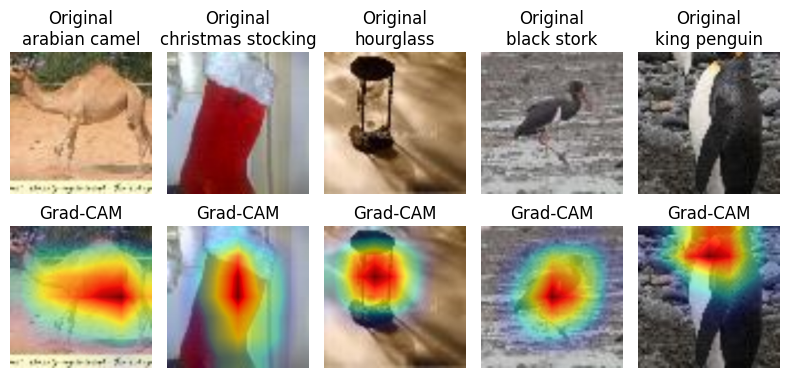

In [8]:
plt.figure(figsize=(8,4))
for i, (image_path, wnid, _, _, _, _) in enumerate(correct_images[19:24]):
    img, pred_class, pred_prob, cam = get_pred_gradcam(image_path)
    
    if imagenet_classes is not None:
        pred_name = imagenet_classes[pred_class]
    else:
        pred_name = str(pred_class)

    true_names = get_tiny_class_names(wnid)
    true_label = true_names[0] if len(true_names) > 0 else wnid
    plt.subplot(2, 5, i + 1)
    plt.imshow(display_transform(img))
    plt.title(f"Original\n{true_label}")
    plt.axis("off")
    plt.subplot(2, 5, i + 6)
    img_resized = display_transform(img)
    img_np = np.array(img_resized)
    plt.imshow(img_np)
    plt.imshow(cam, cmap="jet", alpha=cam)
    plt.title(f"Grad-CAM")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Guided Grad-CAM

In [9]:
for module in model.modules():
    if isinstance(module, nn.ReLU):
        module.inplace = False

In [10]:
class GuidedBackprop:
    def __init__(self, model):
        self.model = model
        self.handles = []

        for module in self.model.modules():
            if isinstance(module, nn.ReLU):
                handle = module.register_full_backward_hook(self.save_relu_backward)
                self.handles.append(handle)

    def save_relu_backward(self, layer, input, output):
        if input[0] is None:
            return None
        guided_grad = torch.clamp(input[0], min=0.0)
        return (guided_grad,)

    def generate(self, input, class_index):
        x = input.clone().detach()
        x.requires_grad = True
        self.model.zero_grad()
        output = self.model(x)
        score = output[0, class_index]
        score.backward()
        guided_grad = x.grad[0].detach().cpu().numpy()
        guided_grad = np.transpose(guided_grad, (1, 2, 0))
        guided_grad = guided_grad - guided_grad.min()
        guided_grad = guided_grad / (guided_grad.max() + 1e-8)
        return guided_grad
    def remove_saves(self):
        for handle in self.handles:
            handle.remove()

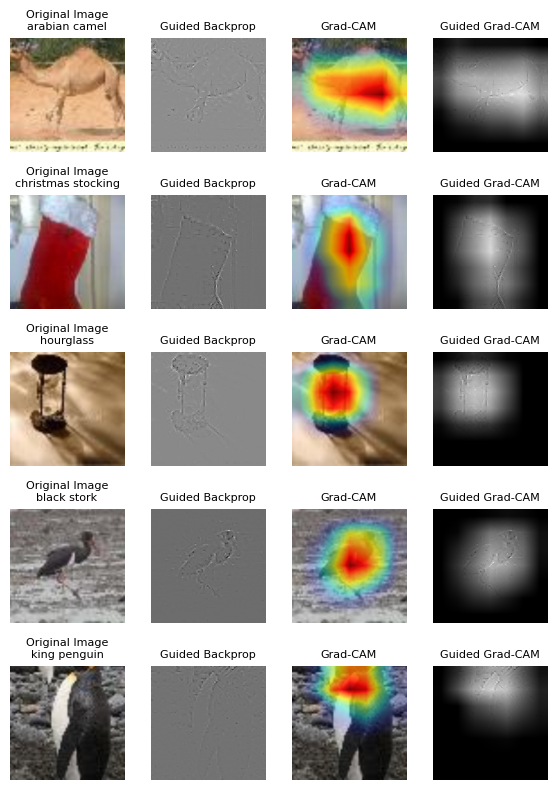

In [11]:
guided_prop = GuidedBackprop(model)
def make_guided_gradcam(guided_backprop, cam):
    cam_3d = np.expand_dims(cam, axis=2)
    guided_gradcam = guided_backprop * cam_3d
    guided_gradcam = guided_gradcam - guided_gradcam.min()
    guided_gradcam = guided_gradcam / (guided_gradcam.max() + 1e-8)
    return guided_gradcam

selected_correct_images = correct_images[19:24]
fig, axes = plt.subplots(5, 4, figsize=(6, 8))
plt.subplots_adjust(wspace=0.15, hspace=0.6)

for row, (image_path, wnid, _, _, _, _) in enumerate(selected_correct_images):
    img = Image.open(image_path).convert("RGB")
    x = transform(img).unsqueeze(0).to(device)
    x.requires_grad = True
    model.eval()
    output = model(x)
    probs = F.softmax(output, dim=1)
    pred_prob, pred_class = torch.max(probs, dim=1)
    pred_class = pred_class.item()
    pred_prob = pred_prob.item()

    if imagenet_classes is not None:
        pred_name = imagenet_classes[pred_class]
    else:
        pred_name = str(pred_class)

    true_names = get_tiny_class_names(wnid)
    true_label = true_names[0] if len(true_names) > 0 else wnid
    cam = gradcam.generate(x, pred_class)
    guided_backprop = guided_prop.generate(x, pred_class)
    guided_gradcam = make_guided_gradcam(guided_backprop, cam)
    img_resized = display_transform(img)
    img_np = np.array(img_resized)

    axes[row, 0].imshow(img_np)
    axes[row, 0].set_title(f"Original Image\n{true_label}", fontsize=8)
    axes[row, 0].axis("off")

    axes[row, 1].imshow(guided_backprop.mean(axis=2), cmap="gray")
    axes[row, 1].set_title("Guided Backprop", fontsize=8)
    axes[row, 1].axis("off")

    axes[row, 2].imshow(img_np)
    axes[row, 2].imshow(cam, cmap="jet", alpha=cam)
    axes[row, 2].set_title(f"Grad-CAM", fontsize=8)
    axes[row, 2].axis("off")

    axes[row, 3].imshow(guided_gradcam.mean(axis=2), cmap="gray")
    axes[row, 3].set_title("Guided Grad-CAM", fontsize=8)
    axes[row, 3].axis("off")

plt.tight_layout()
plt.show()

# Q2 - Part 2 - FinerGrad-CAM

In [12]:
guided_prop.remove_saves()

In [13]:
class FinerGradCAM:
    def __init__(self, model, last_layer):
        self.model = model
        self.last_layer = last_layer
        self.feature_maps = None
        self.gradients = None
        self.forward_handle = self.last_layer.register_forward_hook(self.save_feature_maps)
        self.backward_handle = self.last_layer.register_full_backward_hook(self.save_gradient)

    def save_feature_maps(self, layer, input, output):
        self.feature_maps = output

    def save_gradient(self, layer, input, output):
        self.gradients = output[0]

    def generate(self, input, target_class, similar_classes, gamma=0.6):
        self.model.zero_grad()
        output = self.model(input)
        target_score = output[0, target_class]

        if len(similar_classes) == 0 or gamma == 0:
            score = target_score
        else:
            similar_scores = output[0, similar_classes]
            score = target_score - gamma * similar_scores.mean()

        score.backward()
        gradients = self.gradients
        feature_maps = self.feature_maps
        weights = gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * feature_maps).sum(dim=1, keepdim=True)
        cam = F.relu(cam)
        cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)
        cam = cam.squeeze().detach().cpu().numpy()
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        return cam

In [14]:
last_layer = model.layer4[-1].conv2
finer_gradcam = FinerGradCAM(model, last_layer)
gammas = [0.2, 0.6, 1.0]
d = 3

def get_target_and_similar_classes(image_path, d=3):
    img = Image.open(image_path).convert("RGB")
    x = transform(img).unsqueeze(0).to(device)

    model.eval()

    with torch.no_grad():
        logits = model(x)
        probs = F.softmax(logits, dim=1)

    top_probs, top_classes = torch.topk(probs, k=d + 1, dim=1)

    top_probs = top_probs[0].cpu().numpy()
    top_classes = top_classes[0].cpu().numpy()

    target_class = int(top_classes[0])
    target_prob = float(top_probs[0])

    similar_classes = [int(c) for c in top_classes[1:d + 1]]

    return target_class, target_prob, similar_classes

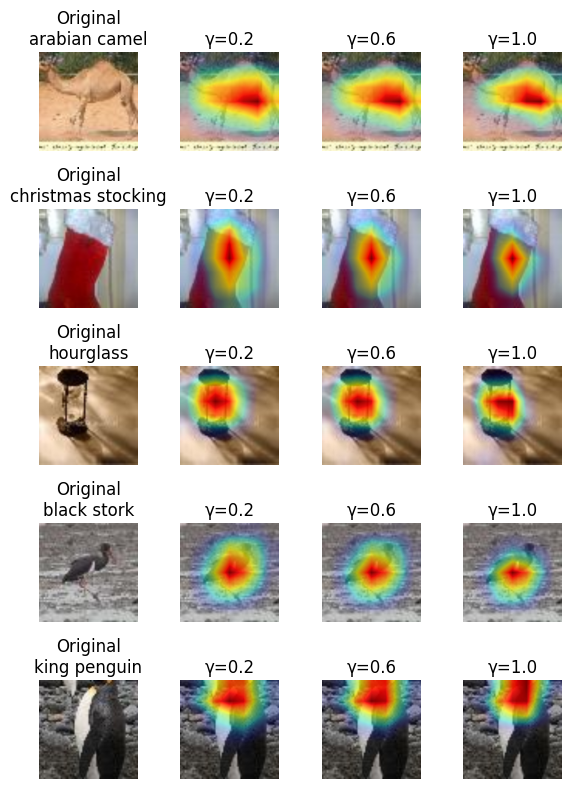

In [15]:
selected_correct_images = correct_images[19:24]
fig, axes = plt.subplots(5, 4, figsize=(6, 8))
plt.subplots_adjust(wspace=0.15, hspace=0.55)

for row, (image_path, wnid, _, _, _, _) in enumerate(selected_correct_images):
    img = Image.open(image_path).convert("RGB")
    img_resized = display_transform(img)
    img_np = np.array(img_resized)
    x = transform(img).unsqueeze(0).to(device)
    x.requires_grad = True
    target_class, target_prob, similar_classes = get_target_and_similar_classes(image_path, d=d)

    if imagenet_classes is not None:
        target_name = imagenet_classes[target_class]
        similar_classes_names = [imagenet_classes[c] for c in similar_classes]
    else:
        target_name = str(target_class)
        similar_classes_names = [str(c) for c in similar_classes]

    true_names = get_tiny_class_names(wnid)
    true_label = true_names[0] if len(true_names) > 0 else wnid

    axes[row, 0].imshow(img_np)
    axes[row, 0].set_title(f"Original\n{true_label}")
    axes[row, 0].axis("off")

    for col, gamma in enumerate(gammas):
        x = transform(img).unsqueeze(0).to(device)
        x.requires_grad = True
        cam = finer_gradcam.generate(input=x, target_class=target_class, similar_classes=similar_classes, gamma=gamma)
        axes[row, col + 1].imshow(img_np)
        axes[row, col + 1].imshow(cam, cmap="jet", alpha=cam)
        axes[row, col + 1].set_title(f"γ={gamma}")
        axes[row, col + 1].axis("off")

plt.tight_layout()
plt.show()

In [16]:
for i, (image_path, wnid, _, _, _, _) in enumerate(selected_correct_images):
    target_class, target_prob, similar_classes = get_target_and_similar_classes(image_path, d=3)
    if imagenet_classes is not None:
        target_name = imagenet_classes[target_class]
        similar_classes_names = [imagenet_classes[c] for c in similar_classes]
    else:
        target_name = str(target_class)
        similar_classes_names = [str(c) for c in similar_classes]
    print("Image", i + 1)
    print("Target class:", target_name, f"| prob:{target_prob:.4f}")
    print("Similar classes:", similar_classes_names)
    print()

Image 1
Target class: Arabian camel | prob:0.9955
Similar classes: ['sorrel', 'hartebeest', 'gazelle']

Image 2
Target class: Christmas stocking | prob:0.7810
Similar classes: ['overskirt', 'Windsor tie', 'velvet']

Image 3
Target class: hourglass | prob:0.5211
Similar classes: ['chime', 'gong', 'guillotine']

Image 4
Target class: black stork | prob:0.9202
Similar classes: ['black grouse', 'limpkin', 'red-breasted merganser']

Image 5
Target class: king penguin | prob:0.5923
Similar classes: ['tusker', 'Mexican hairless', 'curly-coated retriever']



### Comparision

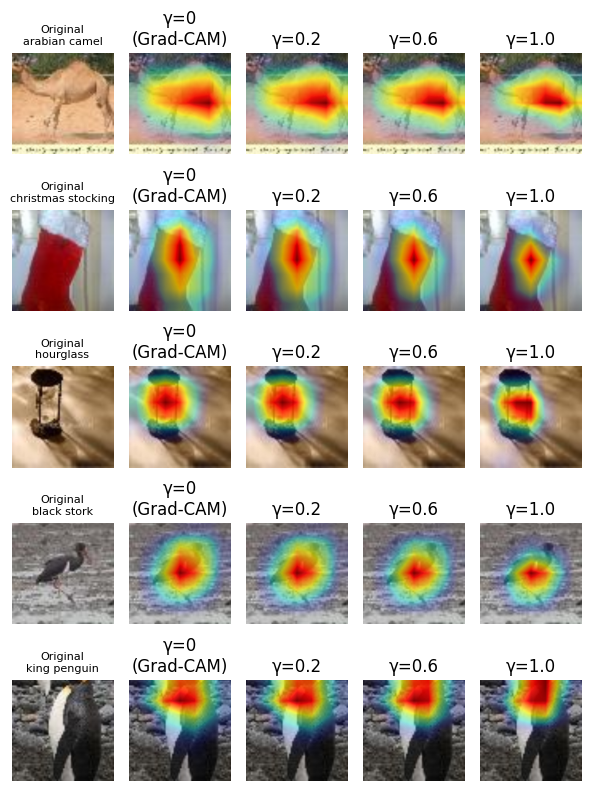

In [17]:
gammas_compare = [0, 0.2, 0.6, 1.0]
selected_correct_images = correct_images[19:24]
fig, axes = plt.subplots(5, 5, figsize=(6, 8))
plt.subplots_adjust(wspace=0.15, hspace=0.55)

for row, (image_path, wnid, _, _, _, _) in enumerate(selected_correct_images):
    img = Image.open(image_path).convert("RGB")
    img_resized = display_transform(img)
    img_np = np.array(img_resized)
    x = transform(img).unsqueeze(0).to(device)
    x.requires_grad = True
    target_class, target_prob, similar_classes = get_target_and_similar_classes(image_path, d=d)

    if imagenet_classes is not None:
        target_name = imagenet_classes[target_class]
        similar_classes_names = [imagenet_classes[c] for c in similar_classes]
    else:
        target_name = str(target_class)
        similar_classes_names = [str(c) for c in similar_classes]

    true_names = get_tiny_class_names(wnid)
    true_label = true_names[0] if len(true_names) > 0 else wnid

    axes[row, 0].imshow(img_np)
    axes[row, 0].set_title(f"Original\n{true_label}", fontsize=8)
    axes[row, 0].axis("off")

    for col, gamma in enumerate(gammas_compare):
        x = transform(img).unsqueeze(0).to(device)
        x.requires_grad = True
        cam = finer_gradcam.generate(input=x, target_class=target_class, similar_classes=similar_classes, gamma=gamma)
        axes[row, col + 1].imshow(img_np)
        axes[row, col + 1].imshow(cam, cmap="jet", alpha=cam)
        if gamma == 0:
            title = "γ=0\n(Grad-CAM)"
            axes[row, col + 1].set_title("γ=0\n(Grad-CAM)")
        else:
            axes[row, col + 1].set_title(f"γ={gamma}")
        axes[row, col + 1].axis("off")

plt.tight_layout()
plt.show()